**Content Based Recommendation using TF-IDF, XGBoost and Hybrid**

The goal is to predict whether a user will view an article or not, and use that score to recommend articles

**Flow of this notebook:**
1. Load and clean the 3 tables (users, history, articles)
2. Merge them into one table
3. Feature engineering
4. Exploration (EDA)
5. Time-based train/test split
6. Model 1 – Baseline: TF-IDF + cosine similarity (pure content-based)
7. Model 2 – XGBoost on user and article behaviour features
8. Model 3 – Hybrid: XGBoost + TF-IDF similarity as an extra feature

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report

from xgboost import XGBClassifier

**LOAD DATA**

In [2]:
data_folder = "C:/Users/User/Documents/VSCode/personal/assessment_sgm/technical-assessment/data/"

user_demographics = pd.read_csv(data_folder + "user_demographics.csv")
user_article_history = pd.read_csv(data_folder + "user_article_history.csv")
article_list = pd.read_csv(data_folder + "article_list.csv")

**DATA UNDERSTANDING AND CLEANING**

In [3]:
print("user_demographics:", user_demographics.shape)
print("user_article_history:", user_article_history.shape)
print("article_list:", article_list.shape)

user_demographics: (305, 6)
user_article_history: (14475, 4)
article_list: (8043, 5)


USER DEMOGRAPHICS

In [4]:
user_demographics.info()

<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   cxuserid         305 non-null    str  
 1   gender           305 non-null    str  
 2   race             305 non-null    str  
 3   city             305 non-null    str  
 4   education_level  305 non-null    str  
 5   occupation       305 non-null    str  
dtypes: str(6)
memory usage: 44.6 KB


In [5]:
# check unique values and its count for every column to understand the data value
for col in user_demographics.columns:
    print("Column:", col)
    print("Unique values:", user_demographics[col].nunique(dropna=False))
    print(user_demographics[col].value_counts(dropna=False))
    print("--------------------------------------------")

Column: cxuserid
Unique values: 305
cxuserid
8758c624-0db7-4998-a854-967521ecd766    1
3ae3a3f6-775c-4727-8faf-bb863361ed4b    1
67f2b6b3-271a-43fc-91a9-0ab54747320f    1
89de1cba-6a55-49fd-b5bf-58f5faf91fe2    1
181ca4b6-d089-4382-9956-793112bee914    1
                                       ..
8eabdd39-23be-4c93-802b-868ed9616978    1
fd1cbe87-39cd-4ed3-a4a1-1de4e53a989b    1
3dc5c511-e7cb-45ef-ad63-3594e8e91437    1
6e26806a-a82a-43b8-9460-af3cc6cbcba4    1
eda94a6d-808b-46ae-a106-6222f854c578    1
Name: count, Length: 305, dtype: int64
--------------------------------------------
Column: gender
Unique values: 2
gender
MALE      203
FEMALE    102
Name: count, dtype: int64
--------------------------------------------
Column: race
Unique values: 4
race
CHINESE    223
MALAY       47
INDIAN      33
OTHERS       2
Name: count, dtype: int64
--------------------------------------------
Column: city
Unique values: 60
city
KUALA LUMPUR                 75
PETALING JAYA                54
SUBAN

In [6]:
# check duplicate user id. user cannot be duplicated
user_demographics["cxuserid"].duplicated().sum()

np.int64(0)

In [7]:
# group education level into few level because got many different spelling
# check education start from highest level first
def clean_education_level(text):
    if not isinstance(text, str):
        return "Unknown"

    text = text.upper().strip()

    if "PHD" in text:
        return "PHD"

    if "MASTER" in text:
        return "MASTER"

    if "DEGREE" in text or "BACHELOR" in text or "HONOURS" in text:
        return "BACHELORS DEGREE"

    if "ADVANCED DIPLOMA" in text or "POST GRADUATE" in text or "POSTGRADUATE" in text:
        return "ADVANCE DIPLOMA"

    if "DIPLOMA" in text:
        return "DIPLOMA"

    if "PROFESSIONAL CERTIFICATE" in text or "VOCATIONAL" in text:
        return "PROFESSIONAL CERTIFICATE"

    if "STPM" in text or "A-LEVEL" in text or "PRE - U" in text or "PRE-U" in text:
        return "PRE-UNIVERSITY"

    if "SPM" in text or "O-LEVEL" in text or "SECONDARY" in text:
        return "SECONDARY SCHOOL"

    if "DISCLOSE" in text or "PREFER NOT" in text:
        return "DISCLOSE"

    return "OTHER"


user_demographics["education_level"] = user_demographics["education_level"].apply(clean_education_level)

USER ARTICLE HISTORY

In [8]:
user_article_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 14475 entries, 0 to 14474
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cxuserid         14475 non-null  str    
 1   record_datetime  14475 non-null  str    
 2   article_id       14467 non-null  float64
 3   is_viewed        14475 non-null  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 1.3 MB


In [9]:
# check missing article id
user_article_history.isna().sum()

cxuserid           0
record_datetime    0
article_id         8
is_viewed          0
dtype: int64

In [10]:
# remove row with no article id instead of replace since 8 rows is small so no effect
user_article_history = user_article_history.dropna(subset=["article_id"])

In [11]:
# convert date str to datetime
user_article_history["record_datetime"] = pd.to_datetime(user_article_history["record_datetime"], format="mixed")

In [12]:
# remove the milliseconds
user_article_history["record_datetime"] = user_article_history["record_datetime"].dt.floor("s")

Same user, same article, same second means same record. Got 918 duplicate.

In [13]:
# check duplicate rows. Same user, article, and time means same record
user_article_history.duplicated(subset=["cxuserid", "article_id", "record_datetime"]).sum()

np.int64(918)

In [14]:
# remove duplicate rows
user_article_history = user_article_history.drop_duplicates(keep="first")

In [15]:
# check date range of the record
print("Min record_datetime:", user_article_history["record_datetime"].min())
print("Max record_datetime:", user_article_history["record_datetime"].max())

Min record_datetime: 2025-01-14 13:41:38
Max record_datetime: 2026-08-21 10:00:51


ARTICLE LIST

In [16]:
article_list.info()

<class 'pandas.DataFrame'>
RangeIndex: 8043 entries, 0 to 8042
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   content_id                8043 non-null   int64
 1   content_title             8043 non-null   str  
 2   content_category          8043 non-null   str  
 3   content_publish_datetime  8043 non-null   str  
 4   content_sentiment         7491 non-null   str  
dtypes: int64(1), str(4)
memory usage: 1.0 MB


In [17]:
# check which article got no sentiment
article_list[article_list["content_sentiment"].isna()]

,content_id,content_title,content_category,content_publish_datetime,content_sentiment
1,1725802,"KL stall serves handmade noodles, with weekend...",Food,2025-10-09 07:00:00,NaN
2,1936917,Taste of Italian coastline comes to KL city ce...,Food,2026-08-15 07:00:00,NaN
3,1932336,Teochew comfort in a bowl,Food,2026-08-08 07:00:00,NaN
4,1931049,Michelin-starred chef brings Korean flavours t...,Food,2026-08-06 08:48:00,NaN
6,1750871,Rice bowl tweak turns soup-rise hit for hawkers,Food,2025-11-13 07:00:00,NaN
...,...,...,...,...,...
7953,1615220,Maybank sets RM200 daily transaction limit for...,Tech,2025-05-06 15:15:00,NaN
7960,1615563,"M&S, Co-op cyberattackers duped IT help desks ...",Tech,2025-05-06 19:38:00,NaN
7979,1610340,Chinese singles are looking for love in video ...,Tech,2025-04-29 13:05:00,NaN
7995,1577905,Cashless crooks target Ramadan bazaar traders ...,Tech,2025-03-14 13:39:00,NaN


In [18]:
# fill missing sentiment with unknown value to preserve the data
article_list["content_sentiment"] = article_list["content_sentiment"].fillna("Unknown")

In [19]:
# check duplicate id. must be unique
article_list["content_id"].duplicated().sum()

np.int64(0)

In [20]:
# convert str date to datetime
article_list["content_publish_datetime"] = pd.to_datetime(article_list["content_publish_datetime"])

In [21]:
# check date range of content publish
print("Min content_publish_datetime:", article_list["content_publish_datetime"].min())
print("Max content_publish_datetime:", article_list["content_publish_datetime"].max())

Min content_publish_datetime: 2020-01-02 07:00:00
Max content_publish_datetime: 2026-08-21 09:19:00


**MERGE ALL DATA INTO ONE DATAFRAME**

In [22]:
# join user info into the history
df = pd.merge(user_demographics, user_article_history, on="cxuserid", how="right")

In [23]:
df["article_id"].isna().sum()

np.int64(0)

In [24]:
df_merge = pd.merge(df, article_list, left_on="article_id", right_on="content_id", how="left")

In [25]:
# check missing value again just in case
df_merge.isna().sum()

cxuserid                     0
gender                       0
race                         0
city                         0
education_level              0
occupation                   0
record_datetime              0
article_id                   0
is_viewed                    0
content_id                  91
content_title               91
content_category            91
content_publish_datetime    91
content_sentiment           91
dtype: int64

In [26]:
# remove row because no title and category, cannot use for content based
df_merge = df_merge.dropna(subset=["content_id"])

In [27]:
# article_id same as content_id so drop it
df_merge = df_merge.drop(columns=["article_id"])

In [28]:
df_merge.info()

<class 'pandas.DataFrame'>
Index: 13458 entries, 0 to 13548
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   cxuserid                  13458 non-null  str           
 1   gender                    13458 non-null  str           
 2   race                      13458 non-null  str           
 3   city                      13458 non-null  str           
 4   education_level           13458 non-null  str           
 5   occupation                13458 non-null  str           
 6   record_datetime           13458 non-null  datetime64[us]
 7   is_viewed                 13458 non-null  int64         
 8   content_id                13458 non-null  float64       
 9   content_title             13458 non-null  str           
 10  content_category          13458 non-null  str           
 11  content_publish_datetime  13458 non-null  datetime64[us]
 12  content_sentiment         13458 no

In [29]:
df_merge["content_id"] = df_merge["content_id"].astype(str)

In [30]:
df_merged = df_merge.copy()

In [31]:
# check duplicate rows after merge
df_merged[df_merged.duplicated(subset=["cxuserid", "content_id", "record_datetime"], keep=False)]

,cxuserid,gender,race,city,education_level,occupation,record_datetime,is_viewed,content_id,content_title,content_category,content_publish_datetime,content_sentiment


After dataframe is clean and proper we can proceed to feature engineering

**FEATURE ENGINEERING**

All features only use data before the current row. If include current row, the model already know the answer (leakage). That is why i use cumsum then minus current row, and rolling with closed left.

Sort by time first because cumsum and rolling follow the row order.

In [32]:
# sort by record_datetime in ascending order
df_merged = df_merged.sort_values("record_datetime", ascending=True)

In [33]:
# article age in hours to get how old the article when user see it
article_age = df_merged["record_datetime"] - df_merged["content_publish_datetime"]
df_merged["article_age_hours"] = article_age.dt.total_seconds() / 3600

In [34]:
# mostly to calculate count view of the user. useful to know how much view before current views
# date where user see the content
df_merged["interaction_date"] = df_merged["record_datetime"].dt.date

# total views of the user before current interaction. cumsum include the current row so need to minus it back
user_cumsum = df_merged.groupby("cxuserid")["is_viewed"].cumsum()
df_merged["user_total_views"] = user_cumsum - df_merged["is_viewed"]

df_merged = df_merged.sort_values(["cxuserid", "record_datetime"])

# total views of the user on the same day before current interaction
today_cumsum = df_merged.groupby(["cxuserid", "interaction_date"])["is_viewed"].cumsum()
df_merged["user_total_views_today"] = today_cumsum - df_merged["is_viewed"]

# total views of the user in the last 7 days and 30 days before current interaction
user_group = df_merged.groupby("cxuserid")
views_7d = user_group.rolling("7D", on="record_datetime", closed="left")["is_viewed"].sum()
views_30d = user_group.rolling("30D", on="record_datetime", closed="left")["is_viewed"].sum()

df_merged["user_views_7d"] = views_7d.to_numpy()
df_merged["user_views_30d"] = views_30d.to_numpy()

# first row of each user got no history, so fill 0
df_merged["user_views_7d"] = df_merged["user_views_7d"].fillna(0)
df_merged["user_views_30d"] = df_merged["user_views_30d"].fillna(0)

In [35]:
# engineer the time features where consist of record on time, day, week type and month.
# useful to know the timing of user interaction
df_merged["hour"] = df_merged["record_datetime"].dt.hour
df_merged["dayofweek"] = df_merged["record_datetime"].dt.dayofweek
df_merged["dayname"] = df_merged["record_datetime"].dt.day_name()
df_merged["is_weekend"] = (df_merged["dayofweek"] >= 5).astype(int)
df_merged["month"] = df_merged["record_datetime"].dt.month
df_merged["dayofmonth"] = df_merged["record_datetime"].dt.day

# minutes since the user previous interaction
time_diff = df_merged.groupby("cxuserid")["record_datetime"].diff()
df_merged["time_since_previous"] = time_diff.dt.total_seconds() / 60
df_merged["time_since_previous"] = df_merged["time_since_previous"].fillna(0)

C:\Users\User\AppData\Local\Temp\ipykernel_8876\1416825499.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_merged["dayofweek"] = df_merged["record_datetime"].dt.dayofweek


In [36]:
# get reading period based on the hour
def get_reading_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"


df_merged["reading_period"] = df_merged["hour"].apply(get_reading_period)

In [37]:
df_merged = df_merged.sort_values("record_datetime", ascending=True)

In [38]:
# count how many times the user view this category (include current row)
df_merged["user_category_views"] = df_merged.groupby(["cxuserid", "content_category"], dropna=False)["is_viewed"].cumsum()

# minus the current row so theres no target leakage
df_merged["user_category_views_before_current"] = df_merged["user_category_views"] - df_merged["is_viewed"]

# calculate category preference to know how each category view history effect user choice
df_merged["user_category_preference"] = df_merged["user_category_views_before_current"] / df_merged["user_total_views"]
df_merged["user_category_preference"] = df_merged["user_category_preference"].fillna(0)

In [39]:
# put 1 if sentiment is positive, negative or neutral, 0 if unknown. take only valid sentiment because got value
df_merged["content_sentiment_valid"] = df_merged["content_sentiment"].isin(["Positive", "Negative", "Neutral"]).astype(int)

# only count the view if the =sentiment is known
df_merged["known_sentiment_view"] = df_merged["is_viewed"] * df_merged["content_sentiment_valid"]

# how many times the user view this sentiment before current row
df_merged["user_sentiment_views"] = df_merged.groupby(["cxuserid", "content_sentiment"], dropna=False)["known_sentiment_view"].cumsum()
df_merged["user_sentiment_views_before_current"] = df_merged["user_sentiment_views"] - df_merged["known_sentiment_view"]

# how many known sentiment views the user got before current row
df_merged["user_known_sentiment_views"] = df_merged.groupby("cxuserid")["known_sentiment_view"].cumsum()
df_merged["user_historical_known_sentiment_views"] = df_merged["user_known_sentiment_views"] - df_merged["known_sentiment_view"]

# calculate sentiment preference to know how each sentiment view history effect user choice
df_merged["user_sentiment_preference"] = df_merged["user_sentiment_views_before_current"] / df_merged["user_historical_known_sentiment_views"]
df_merged["user_sentiment_preference"] = df_merged["user_sentiment_preference"].fillna(0)

In [40]:
# article views before current row
article_cumsum = df_merged.groupby("content_id")["is_viewed"].cumsum()
df_merged["article_total_views"] = article_cumsum - df_merged["is_viewed"]

# article impressions before current row (cumcount start from 0)
df_merged["article_total_impressions"] = df_merged.groupby("content_id").cumcount()

# article view rate = views / impressions. important to know rating of the article high or low
df_merged["article_view_rate"] = df_merged["article_total_views"] / df_merged["article_total_impressions"]
df_merged["article_view_rate"] = df_merged["article_view_rate"].fillna(0)

In [41]:
# article views in the last 7 days and 30 days before current row
df_merged = df_merged.sort_values(["content_id", "record_datetime"])
df_merged = df_merged.reset_index(drop=True)

article_group = df_merged.groupby("content_id")
article_7d = article_group.rolling("7D", on="record_datetime", closed="left")["is_viewed"].sum()
article_30d = article_group.rolling("30D", on="record_datetime", closed="left")["is_viewed"].sum()

df_merged["article_recent_views_7d"] = article_7d.fillna(0).to_numpy()
df_merged["article_recent_views_30d"] = article_30d.fillna(0).to_numpy()

In [42]:
df_merged.columns

Index(['cxuserid', 'gender', 'race', 'city', 'education_level', 'occupation',
       'record_datetime', 'is_viewed', 'content_id', 'content_title',
       'content_category', 'content_publish_datetime', 'content_sentiment',
       'article_age_hours', 'interaction_date', 'user_total_views',
       'user_total_views_today', 'user_views_7d', 'user_views_30d', 'hour',
       'dayofweek', 'dayname', 'is_weekend', 'month', 'dayofmonth',
       'time_since_previous', 'reading_period', 'user_category_views',
       'user_category_views_before_current', 'user_category_preference',
       'content_sentiment_valid', 'known_sentiment_view',
       'user_sentiment_views', 'user_sentiment_views_before_current',
       'user_known_sentiment_views', 'user_historical_known_sentiment_views',
       'user_sentiment_preference', 'article_total_views',
       'article_total_impressions', 'article_view_rate',
       'article_recent_views_7d', 'article_recent_views_30d'],
      dtype='str')

**EXPLORATORY DATA ANALYSIS**

In [43]:
eda = df_merged.copy()

In [44]:
# double check the data
# missing values
missing = pd.DataFrame()
missing["Missing Count"] = eda.isnull().sum()
missing["Missing Percentage"] = eda.isnull().mean() * 100
missing = missing.sort_values("Missing Percentage", ascending=False)
display(missing)

print("Duplicate rows:", eda.duplicated().sum())
print("Unique Users:", eda["cxuserid"].nunique())
print("Unique Articles:", eda["content_id"].nunique())
print("Unique Categories:", eda["content_category"].nunique())

,Missing Count,Missing Percentage
cxuserid,0,0.0
gender,0,0.0
race,0,0.0
city,0,0.0
education_level,0,0.0
occupation,0,0.0
record_datetime,0,0.0
is_viewed,0,0.0
content_id,0,0.0
content_title,0,0.0


Duplicate rows: 0
Unique Users: 305
Unique Articles: 8043
Unique Categories: 11


Find distribution of views and non-views

is_viewed
1    8032
0    5426
Name: count, dtype: int64

Percentage Distribution:
is_viewed
1    59.681974
0    40.318026
Name: proportion, dtype: float64


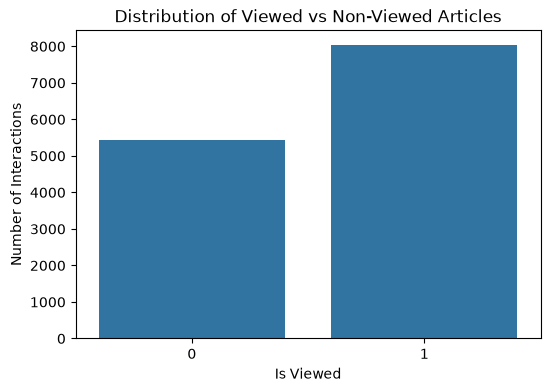

In [45]:
print(eda["is_viewed"].value_counts())

print()
print("Percentage Distribution:")
print(eda["is_viewed"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=eda, x="is_viewed")
plt.title("Distribution of Viewed vs Non-Viewed Articles")
plt.xlabel("Is Viewed")
plt.ylabel("Number of Interactions")
plt.show()

Check views per user. Average is 26 and median is 28 which is close. so no few users take all the views.

In [46]:
# how many views each user got
user_views = eda.groupby("cxuserid")["is_viewed"].sum()

print("Average Views per User:", user_views.mean())
print("Median Views per User:", user_views.median())
print("Maximum Views:", user_views.max())

Average Views per User: 26.334426229508196
Median Views per User: 28.0
Maximum Views: 62


Find top user with most interaction and views

In [47]:
user_cols = ["cxuserid", "gender", "race", "city", "education_level", "occupation"]

top_users = eda.groupby(user_cols, as_index=False).agg(
    total_interactions=("is_viewed", "count"),
    total_views=("is_viewed", "sum")
)
top_users = top_users.sort_values("total_views", ascending=False)

top_users.head(10)

,cxuserid,gender,race,city,education_level,occupation,total_interactions,total_views
261,ddf8e3f0-8b8d-4465-81ab-2597708be2d1,MALE,CHINESE,KUALA LUMPUR,BACHELORS DEGREE,"PMEB (PROFESSIONALS, MANAGERS, EXECUTIVES AND ...",914,62
89,4f2a124a-b263-417f-8354-0a8c7c94b3bd,MALE,CHINESE,PUCHONG,MASTER,"PMEB (PROFESSIONALS, MANAGERS, EXECUTIVES AND ...",895,37
285,f20fa03c-78b4-4d26-954f-28c6d2ca00b3,FEMALE,MALAY,SHAH ALAM,PRE-UNIVERSITY,STUDENT,30,30
286,f332609b-0c34-4670-8beb-76e7147d85ba,FEMALE,INDIAN,BANDAR PUNCAK ALAM,MASTER,BRAND TRANSCREATOR,30,30
287,f3a68161-7f3e-4e40-8e17-052f5655a653,MALE,CHINESE,PETALING JAYA,BACHELORS DEGREE,NO ANSWER,30,30
280,ee2b4c8b-9079-4764-86b4-0579db588f4a,FEMALE,OTHERS,AMPANG,BACHELORS DEGREE,"PMEB (PROFESSIONALS, MANAGERS, EXECUTIVES AND ...",30,30
283,f162ac0c-0232-441b-ad14-a95c6833a938,MALE,CHINESE,KAJANG,PHD,UNEMPLOYED/ RETIRED,30,30
28,13a0bad8-c12c-4bd3-9e8e-fde9adedb7d3,MALE,CHINESE,KUALA LUMPUR,SECONDARY SCHOOL,SALES EXECUTIVE,30,30
277,ec3035d0-cc6f-4d0a-b11d-7537fb3866d6,MALE,CHINESE,BUKIT MERTAJAM,BACHELORS DEGREE,"PMEB (PROFESSIONALS, MANAGERS, EXECUTIVES AND ...",30,30
25,0fcd42ff-4159-4dba-b270-343b80308aa3,MALE,CHINESE,PUCHONG,BACHELORS DEGREE,DEPARTMENT MANAGER,30,30


Find number of views by content

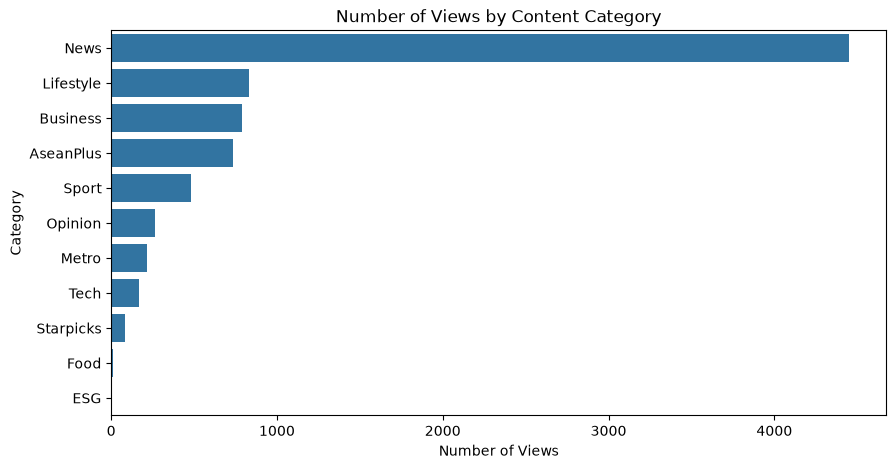

In [48]:
viewed = eda[eda["is_viewed"] == 1]
category_count = viewed["content_category"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=category_count.values, y=category_count.index)
plt.title("Number of Views by Content Category")
plt.xlabel("Number of Views")
plt.ylabel("Category")
plt.show()

Find view rate for each content category

In [49]:
category_views = eda.groupby("content_category").agg(
    total_interactions=("is_viewed", "count"),
    total_views=("is_viewed", "sum")
)
category_views["view_rate"] = category_views["total_views"] / category_views["total_interactions"] * 100

display(category_views.sort_values("total_views", ascending=False))

,total_interactions,total_views,view_rate
content_category,,,
News,8827,4452,50.436162
Lifestyle,845,829,98.106509
Business,847,788,93.034238
AseanPlus,1191,732,61.460957
Sport,653,480,73.506891
Opinion,553,263,47.558770
Metro,241,218,90.456432
Tech,200,169,84.500000
Starpicks,84,84,100.000000


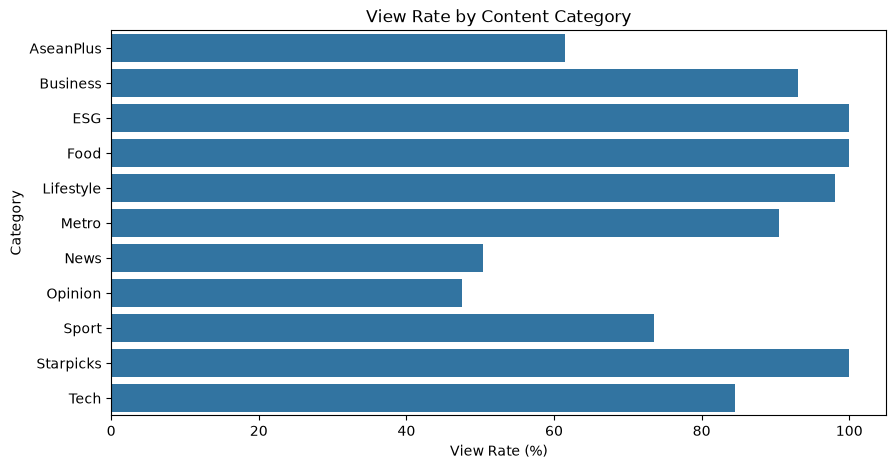

In [50]:
# plot the category views
plt.figure(figsize=(10, 5))
sns.barplot(data=category_views.reset_index(), x="view_rate", y="content_category")
plt.title("View Rate by Content Category")
plt.xlabel("View Rate (%)")
plt.ylabel("Category")
plt.show()

Find distribution of content sentiment

content_sentiment
Neutral     6734
Negative    5684
Unknown      945
Positive      95
Name: count, dtype: int64


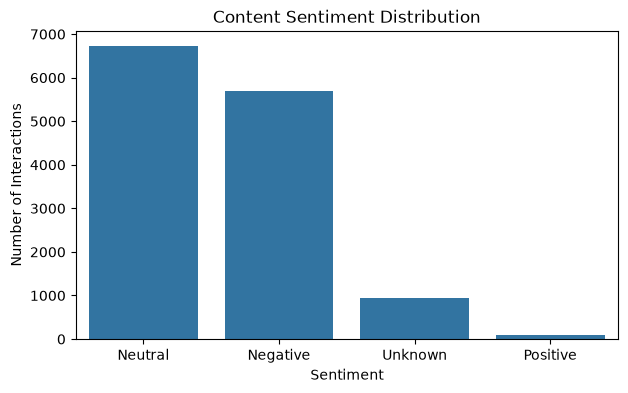

In [51]:
print(eda["content_sentiment"].value_counts())

sentiment_order = eda["content_sentiment"].value_counts().index

plt.figure(figsize=(7, 4))
sns.countplot(data=eda, x="content_sentiment", order=sentiment_order)
plt.title("Content Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Interactions")
plt.show()

In [52]:
# interactions, views and view rate for each sentiment
sentiment_analysis = eda.groupby("content_sentiment").agg(
    interactions=("is_viewed", "count"),
    views=("is_viewed", "sum"),
    view_rate=("is_viewed", "mean")
)
sentiment_analysis["view_rate"] = sentiment_analysis["view_rate"] * 100

sentiment_analysis

,interactions,views,view_rate
content_sentiment,,,
Negative,5684,3081,54.204785
Neutral,6734,4207,62.474012
Positive,95,68,71.578947
Unknown,945,676,71.534392


Unknown got decent value which is good to keep

Check when user read, by hour, by day and weekday vs weekend.

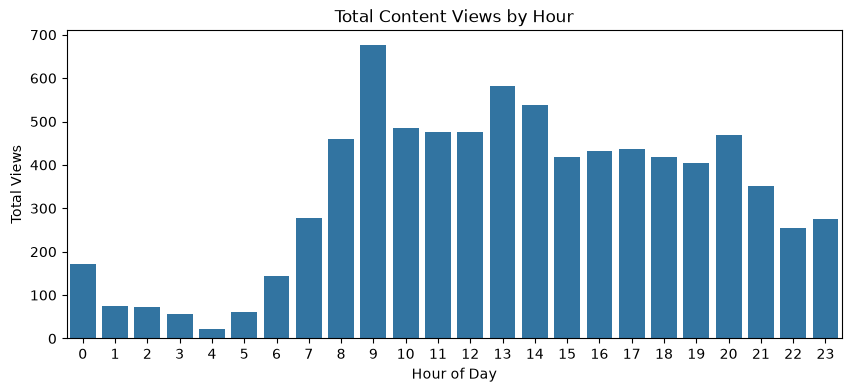

In [53]:
# total views by hour
hourly_views = eda.groupby("hour")["is_viewed"].sum()

plt.figure(figsize=(10, 4))
sns.barplot(x=hourly_views.index, y=hourly_views.values)
plt.title("Total Content Views by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Views")
plt.show()

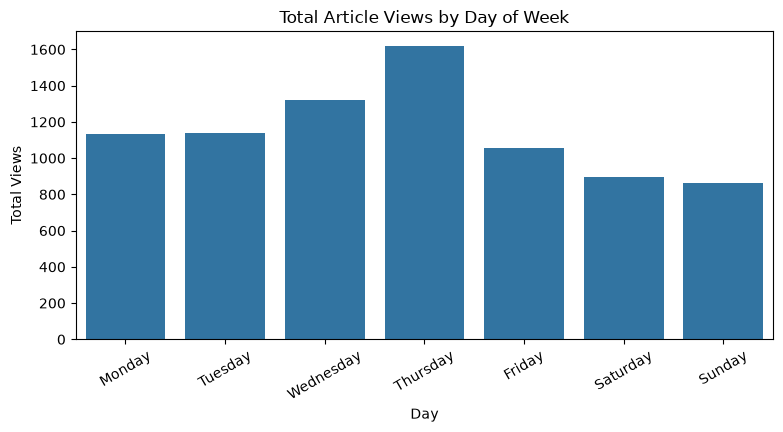

In [54]:
# total views by day of week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

daily_views = eda.groupby("dayname")["is_viewed"].sum()
daily_views = daily_views.reindex(day_order)

plt.figure(figsize=(9, 4))
sns.barplot(x=daily_views.index, y=daily_views.values)
plt.title("Total Article Views by Day of Week")
plt.xlabel("Day")
plt.ylabel("Total Views")
plt.xticks(rotation=30)
plt.show()

In [55]:
# weekday vs weekend
weekend_analysis = eda.groupby("is_weekend").agg(
    interactions=("is_viewed", "count"),
    views=("is_viewed", "sum"),
    view_rate=("is_viewed", "mean")
)
weekend_analysis["view_rate"] = weekend_analysis["view_rate"] * 100

display(weekend_analysis)

,interactions,views,view_rate
is_weekend,,,
0,10130,6273,61.924975
1,3328,1759,52.854567


Top popular article

In [56]:
# top 10 article with most views
top_articles = eda.groupby("content_title").agg(
    total_views=("is_viewed", "sum"),
    total_interactions=("is_viewed", "count")
)
top_articles = top_articles.sort_values("total_views", ascending=False)
top_articles = top_articles.head(10)

top_articles

,total_views,total_interactions
content_title,,
Nightmare as family break turns deadly,22,22
Indonesian beauty queen Putri Andriani Juficha dies at 25,21,21
Saving Selangor from green/blue wave,21,21
"Anwar to make important announcements on Aug 30, Sept 16",21,21
"Immigration lorry hit by car just before fatal crash, say cops",20,20
Syed Saddiq and Bella to tie the knot on Oct 10,18,18
Rocky’s owner charged in court for keeping unlicensed dog in Klang,17,17
"PM's Taiwan remarks not discussed by Cabinet, says Fahmi",17,17
A noisy weekend for PMX,16,16


Check if older article get less view.

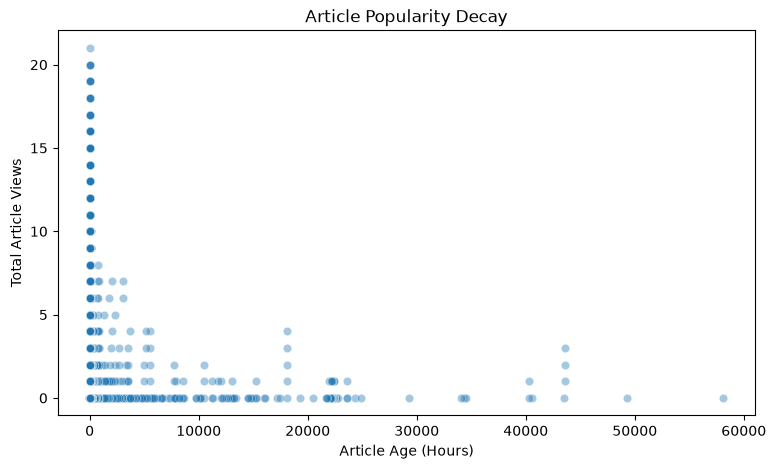

In [57]:
# article age vs article views
plt.figure(figsize=(9, 5))
sns.scatterplot(data=eda, x="article_age_hours", y="article_total_views", alpha=0.4)
plt.title("Article Popularity Decay")
plt.xlabel("Article Age (Hours)")
plt.ylabel("Total Article Views")
plt.show()

Scatter plot hard to see, so group age into buckets and compare.

In [58]:
# group article age into few groups
age_bins = [0, 6, 12, 24, 48, 72, 168, float("inf")]
age_labels = ["0-6 Hours", "6-12 Hours", "12-24 Hours", "1-2 Days", "2-3 Days", "3-7 Days", "Above 7 Days"]

eda["article_age_group"] = pd.cut(eda["article_age_hours"], bins=age_bins, labels=age_labels)

popularity_decay = eda.groupby("article_age_group", observed=False).agg(
    total_articles=("content_id", "nunique"),
    average_views=("article_total_views", "mean"),
    average_view_rate=("article_view_rate", "mean")
)

popularity_decay

,total_articles,average_views,average_view_rate
article_age_group,,,
0-6 Hours,2994,0.852300,0.354999
6-12 Hours,753,1.552284,0.423350
12-24 Hours,1806,0.557838,0.167495
1-2 Days,1932,0.326981,0.111075
2-3 Days,857,0.477451,0.125580
3-7 Days,534,0.554700,0.194530
Above 7 Days,390,0.555079,0.255603


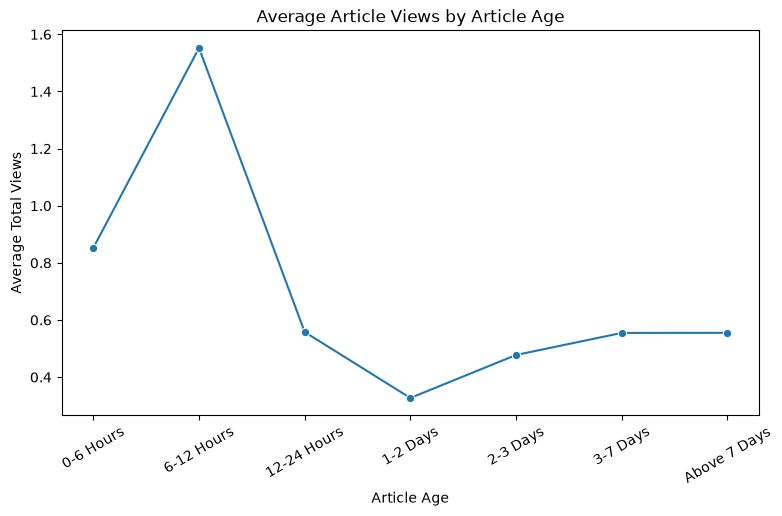

In [59]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=popularity_decay.reset_index(), x="article_age_group", y="average_views", marker="o")
plt.title("Average Article Views by Article Age")
plt.xlabel("Article Age")
plt.ylabel("Average Total Views")
plt.xticks(rotation=30)
plt.show()

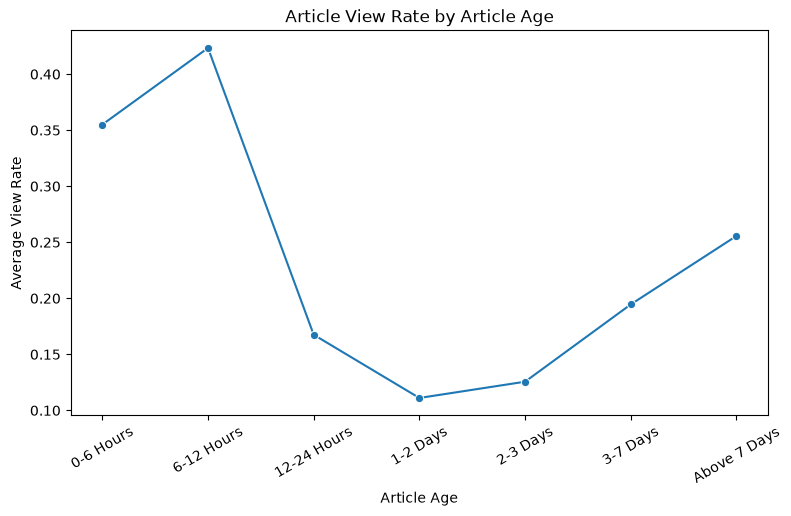

In [60]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=popularity_decay.reset_index(), x="article_age_group", y="average_view_rate", marker="o")
plt.title("Article View Rate by Article Age")
plt.xlabel("Article Age")
plt.ylabel("Average View Rate")
plt.xticks(rotation=30)
plt.show()

Article get most view in first 12 hours then drop a lot. So article age is important.

Check if gender or education change the view rate.

In [61]:
# interactions, views and view rate for each gender
gender_analysis = eda.groupby("gender").agg(
    interactions=("is_viewed", "count"),
    views=("is_viewed", "sum"),
    view_rate=("is_viewed", "mean")
)
gender_analysis["view_rate"] = gender_analysis["view_rate"] * 100

display(gender_analysis)

,interactions,views,view_rate
gender,,,
FEMALE,4449,2602,58.485053
MALE,9009,5430,60.273060


In [62]:
# interactions, views and view rate for each education level
education_analysis = eda.groupby("education_level")["is_viewed"].agg(["count", "sum", "mean"])
education_analysis["mean"] = education_analysis["mean"] * 100

display(education_analysis.sort_values("sum", ascending=False))

,count,sum,mean
education_level,,,
BACHELORS DEGREE,6157,4323,70.212766
MASTER,2461,1603,65.136124
DIPLOMA,1399,512,36.597570
PRE-UNIVERSITY,428,428,100.000000
SECONDARY SCHOOL,2272,425,18.705986
PROFESSIONAL CERTIFICATE,290,290,100.000000
DISCLOSE,195,195,100.000000
ADVANCE DIPLOMA,145,145,100.000000
PHD,111,111,100.000000


Gender almost same. Education very different. Some group like PhD and Pre university got 100 percent view rate because those users dont have any non view rows. So the model can use education as shortcut, need to be careful.

Check correlation between number features

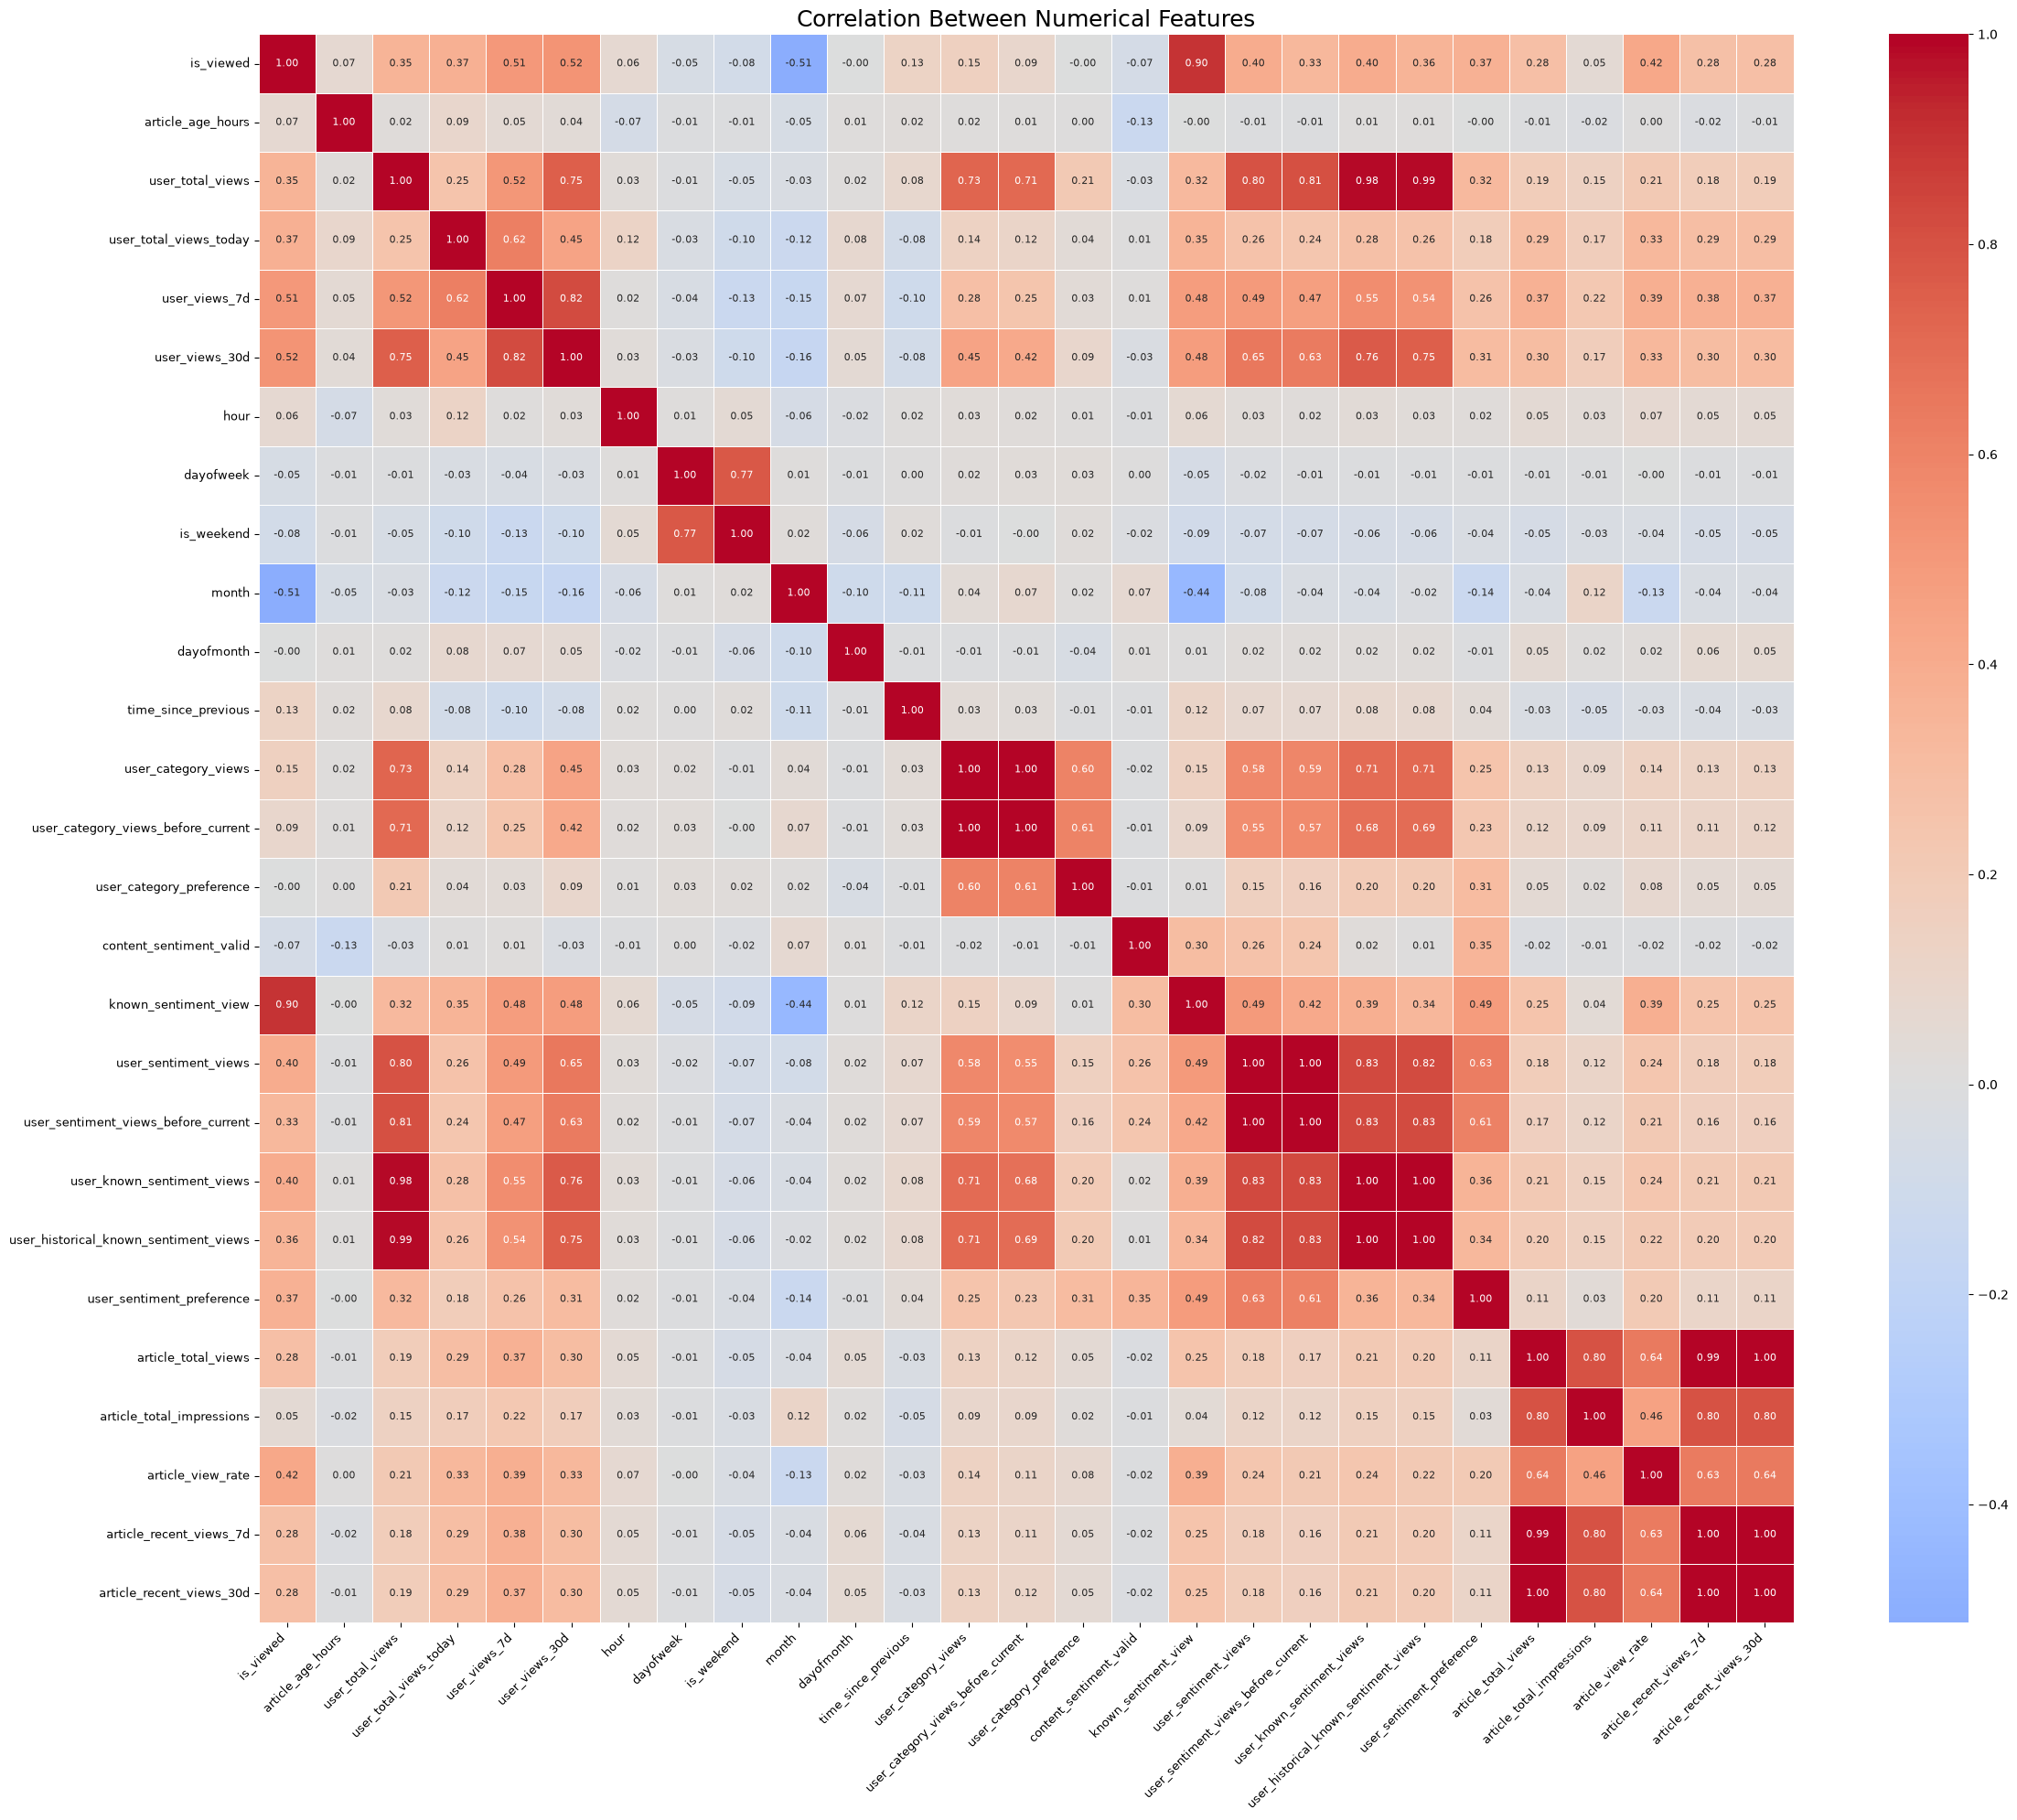

In [63]:
correlation = eda.select_dtypes(include="number").corr()

plt.figure(figsize=(24, 20))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features", fontsize=18)
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

**SPLIT TRAINING AND TESTING**

In [64]:
df_merge = df_merged.copy()

In [65]:
# join title + category + sentiment into 1 text column for tf-idf
# So can match article with same category and sentiment too
df_merge["content_text"] = df_merge["content_title"].fillna("") + " " + df_merge["content_category"].fillna("") + " " + df_merge["content_sentiment"].fillna("")

# clean the text
df_merge["content_text"] = df_merge["content_text"].str.lower()
df_merge["content_text"] = df_merge["content_text"].str.replace(r"[^\w\s]", " ", regex=True)  # remove symbols
df_merge["content_text"] = df_merge["content_text"].str.replace(r"\d+", " ", regex=True)  # remove numbers
df_merge["content_text"] = df_merge["content_text"].str.replace(r"\s+", " ", regex=True)  # remove extra spaces
df_merge["content_text"] = df_merge["content_text"].str.strip()

For each user, sort by time the first 80% for train and last 20% for test. If split random there will be data leakage on chronological value during training. Split per user so every user got in train and test.

In [66]:
# Sort each user records chronological order
df_merge = df_merge.sort_values(["cxuserid", "record_datetime"]).copy()

# get row number by user id and total number
df_merge["row_number"] = (df_merge.groupby("cxuserid").cumcount())

df_merge["total_records"] = (df_merge.groupby("cxuserid")["cxuserid"].transform("count"))

# then split 80 percent of total rows for each user
df_merge["train_limit"] = (df_merge["total_records"] * 0.80).apply(np.floor)

df_train = df_merge[df_merge["row_number"] < df_merge["train_limit"]].copy()

df_test = df_merge[df_merge["row_number"] >= df_merge["train_limit"]].copy()

print("Training:", df_train.shape)
print("Testing:", df_test.shape)

print("\nTraining target:")
print(df_train["is_viewed"].value_counts())

print("\nTesting target:")
print(df_test["is_viewed"].value_counts())

Training: (10693, 46)
Testing: (2765, 46)

Training target:
is_viewed
1    6313
0    4380
Name: count, dtype: int64

Testing target:
is_viewed
1    1719
0    1046
Name: count, dtype: int64


**MODEL 1: BASELINE MODEL (TF-IDF + COSINE SIMILARITY)**

In [67]:
# fit tf-idf using training articles data only
df_train_baseline = df_train[["content_id", "content_text"]].drop_duplicates(subset="content_id")
df_train_baseline = df_train_baseline.reset_index(drop=True)

tfidf = TfidfVectorizer(max_features=5000, stop_words="english", ngram_range=(1, 2))
tfidf.fit(df_train_baseline["content_text"])

print("Unique training contents:", df_train_baseline.shape)
print("Vocab size:", len(tfidf.vocabulary_))

Unique training contents: (6868, 2)
Vocab size: 5000


User profile is average of TF-IDF of all the articles user viewed in train. This is what the user like to read.

In [68]:
# user profile = average tf-idf vector of the articles the user already viewed
user_profile = {}

viewed_train = df_train[df_train["is_viewed"] == 1]

for user_id in viewed_train["cxuserid"].unique():
    user_text = viewed_train[viewed_train["cxuserid"] == user_id]["content_text"]
    user_vectors = tfidf.transform(user_text)
    user_profile[user_id] = np.asarray(user_vectors.mean(axis=0))

print("Total user profile:", len(user_profile))

Total user profile: 303


PLAY AROUND WITH PREDICTION (BASELINE)

In [69]:
threshold = 0.15 # can play around with the threshold to determine the performance of the model

df_test_base_result = df_test.copy()
df_test_vectors = tfidf.transform(df_test["content_text"])

test_score = []

for i in range(len(df_test)):
    user_id = df_test["cxuserid"].iloc[i]

    if user_id not in user_profile:
        test_score.append(0)
        continue

    score = cosine_similarity(df_test_vectors[i], user_profile[user_id])[0][0]
    test_score.append(score)

df_test_base_result["score"] = test_score
df_test_base_result["predicted"] = (df_test_base_result["score"] >= threshold).astype(int)

In [70]:
# evaluate baseline using test data
y_test_base = df_test_base_result["is_viewed"].values
y_score_base = df_test_base_result["score"].values

y_pred_base = (y_score_base >= threshold).astype(int)

evaluation = {}
evaluation["Accuracy"] = accuracy_score(y_test_base, y_pred_base)
evaluation["Precision"] = precision_score(y_test_base, y_pred_base, zero_division=0)
evaluation["Recall"] = recall_score(y_test_base, y_pred_base, zero_division=0)
evaluation["F1 Score"] = f1_score(y_test_base, y_pred_base, zero_division=0)

if len(np.unique(y_test_base)) == 2:
    evaluation["ROC-AUC"] = roc_auc_score(y_test_base, y_score_base)
else:
    evaluation["ROC-AUC"] = np.nan

baseline_test_evaluation = pd.DataFrame(evaluation.items(), columns=["Metric", "Score"])

display(baseline_test_evaluation)
print(classification_report(y_test_base, y_pred_base, zero_division=0))

,Metric,Score
0,Accuracy,0.490778
1,Precision,0.961424
2,Recall,0.188482
3,F1 Score,0.315175
4,ROC-AUC,0.817006


              precision    recall  f1-score   support

           0       0.43      0.99      0.59      1046
           1       0.96      0.19      0.32      1719

    accuracy                           0.49      2765
   macro avg       0.69      0.59      0.45      2765
weighted avg       0.76      0.49      0.42      2765



Precision 0.96 but recall only 0.19. When it say viewed it is mostly correct but it miss most of the views. ROC-AUC 0.82 so the ranking is ok, threshold just too high. Text only is not enough because user also read article not similar to before, like breaking news. So next try XGBoost

List some users that got profile to try

In [71]:
# list some users in test set that can try (must have reading history in training)
known_users = df_test[df_test["cxuserid"].isin(user_profile.keys())]
print(known_users["cxuserid"].unique()[:10])

<ArrowStringArray>
['0017f8be-28cd-49f1-aa8f-f202d75222cb',
 '007ccc46-f247-4b3b-b50e-8557ad26ceb1',
 '01648aeb-e021-4c34-a1be-c52933e55814',
 '01b2ee61-291a-4fbb-9a9a-6c2dbfd632fc',
 '01c28e9a-e7eb-4036-bf99-81a74aa96200',
 '023e691e-e9af-4ef9-922f-03f8d9e09fea',
 '03321f18-5d79-447d-b08c-1182a013c408',
 '036df480-dc87-4866-9b94-b3b496ce5b16',
 '03c18872-a046-4509-a903-487200e1a867',
 '04728661-aa40-48e4-a05a-346866e33693']
Length: 10, dtype: str


Show top articles for one user sort by score, compare with what they really viewed

In [72]:
# change the cxuserid here to try other user
known_users = df_test[df_test["cxuserid"].isin(user_profile.keys())]
user_id = known_users["cxuserid"].iloc[0]

# take only this user rows
user_result = df_test_base_result[df_test_base_result["cxuserid"] == user_id]

# sort by score, highest first
user_result = user_result.sort_values("score", ascending=False)

# remove same article that appear many times
user_result = user_result.drop_duplicates(subset="content_id")

print("User:", user_id)
print("Predicted viewed")
display(user_result[["content_id", "content_title", "content_category", "score", "predicted", "is_viewed"]].head())

User: 0017f8be-28cd-49f1-aa8f-f202d75222cb
Predicted viewed


,content_id,content_title,content_category,score,predicted,is_viewed
10361,1931233.0,Australia politician admits texting 'my job is...,AseanPlus,0.261857,1,1
10688,1933987.0,Oil rises 3% as Iran tempers hopes of Hormuz r...,AseanPlus,0.051527,0,1
10356,1931204.0,MRCB secures RM3.03bil Penang LRT rail systems...,Business,0.050001,0,1
11485,1937585.0,Ramanan calls for Anwar to serve second term a...,News,0.035389,0,1


MODEL 2: XGBOOST

Choose features. No time features because of the 13:30 problem. No city (60 values) and occupation (132 values) because too many for 305 users. No user id and content id because it is id only

In [73]:
# all non-view rows are at 13:30:00, so time features (hour, reading_period, time_since_previous etc)
# will give the answer to the model straight away (roc-auc = 1.0), so dont use time features
categorical = [
    "gender",
    "race",
    "education_level",
    "content_category",
    "content_sentiment"
]

numerical = [
    "article_age_hours",
    "user_total_views",
    "user_category_views_before_current",
    "user_category_preference",
    "user_sentiment_views_before_current",
    "user_historical_known_sentiment_views",
    "user_sentiment_preference",
    "article_total_views",
    "article_total_impressions",
    "article_view_rate"
]

target = "is_viewed"

ENCODE CATEGORICAL DATA

One hot encode so each category become 0 or 1 column because XGBoost need number. Test use reindex so the columns same as train

In [74]:
# take only the columns we need
train_data = df_train[categorical + numerical].copy()
test_data = df_test[categorical + numerical].copy()

# one hot encode categorical columns (each category become a 0/1 column)
train_data = pd.get_dummies(train_data, columns=categorical)
test_data = pd.get_dummies(test_data, columns=categorical)

# test must have the same columns as train
# category not in train will be dropped, missing category fill with 0
test_data = test_data.reindex(columns=train_data.columns, fill_value=0)

X_train = train_data.astype(float)
X_test = test_data.astype(float)

y_train = df_train[target]
y_test = df_test[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (10693, 40)
X_test: (2765, 40)


Save feature names for importance chart later

In [75]:
# feature names after encode
feature_names = list(X_train.columns)

print(feature_names)

['article_age_hours', 'user_total_views', 'user_category_views_before_current', 'user_category_preference', 'user_sentiment_views_before_current', 'user_historical_known_sentiment_views', 'user_sentiment_preference', 'article_total_views', 'article_total_impressions', 'article_view_rate', 'gender_FEMALE', 'gender_MALE', 'race_CHINESE', 'race_INDIAN', 'race_MALAY', 'race_OTHERS', 'education_level_ADVANCE DIPLOMA', 'education_level_BACHELORS DEGREE', 'education_level_DIPLOMA', 'education_level_DISCLOSE', 'education_level_MASTER', 'education_level_PHD', 'education_level_PRE-UNIVERSITY', 'education_level_PROFESSIONAL CERTIFICATE', 'education_level_SECONDARY SCHOOL', 'content_category_AseanPlus', 'content_category_Business', 'content_category_ESG', 'content_category_Food', 'content_category_Lifestyle', 'content_category_Metro', 'content_category_News', 'content_category_Opinion', 'content_category_Sport', 'content_category_Starpicks', 'content_category_Tech', 'content_sentiment_Negative', '

TRAIN XGBOOST

300 trees with small learning rate so learn slowly and more stable. max_depth 5 so not too deep. subsample and colsample 0.8 to reduce overfit. random_state 42 so same result every run.

In [76]:
# train xgboost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="auc",
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


EVALUATE XGBOOST

In [77]:
# predict on test set
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# roc-auc need both 0 and 1 inside test, if not give nan
if y_test.nunique() == 2:
    roc_auc = roc_auc_score(y_test, y_prob)
else:
    roc_auc = np.nan

evaluation = {}
evaluation["Accuracy"] = accuracy_score(y_test, y_pred)
evaluation["Precision"] = precision_score(y_test, y_pred, zero_division=0)
evaluation["Recall"] = recall_score(y_test, y_pred, zero_division=0)
evaluation["F1 Score"] = f1_score(y_test, y_pred, zero_division=0)
evaluation["ROC-AUC"] = roc_auc

evaluation_df = pd.DataFrame(evaluation.items(), columns=["Metric", "Score"])
display(evaluation_df)

print(classification_report(y_test, y_pred, zero_division=0))

,Metric,Score
0,Accuracy,0.936347
1,Precision,0.948807
2,Recall,0.948807
3,F1 Score,0.948807
4,ROC-AUC,0.984867


              precision    recall  f1-score   support

           0       0.92      0.92      0.92      1046
           1       0.95      0.95      0.95      1719

    accuracy                           0.94      2765
   macro avg       0.93      0.93      0.93      2765
weighted avg       0.94      0.94      0.94      2765



Much better than baseline. F1 from 0.32 to 0.95 and ROC-AUC from 0.82 to 0.98. User history and article popularity help a lot

See which features the model use the most.

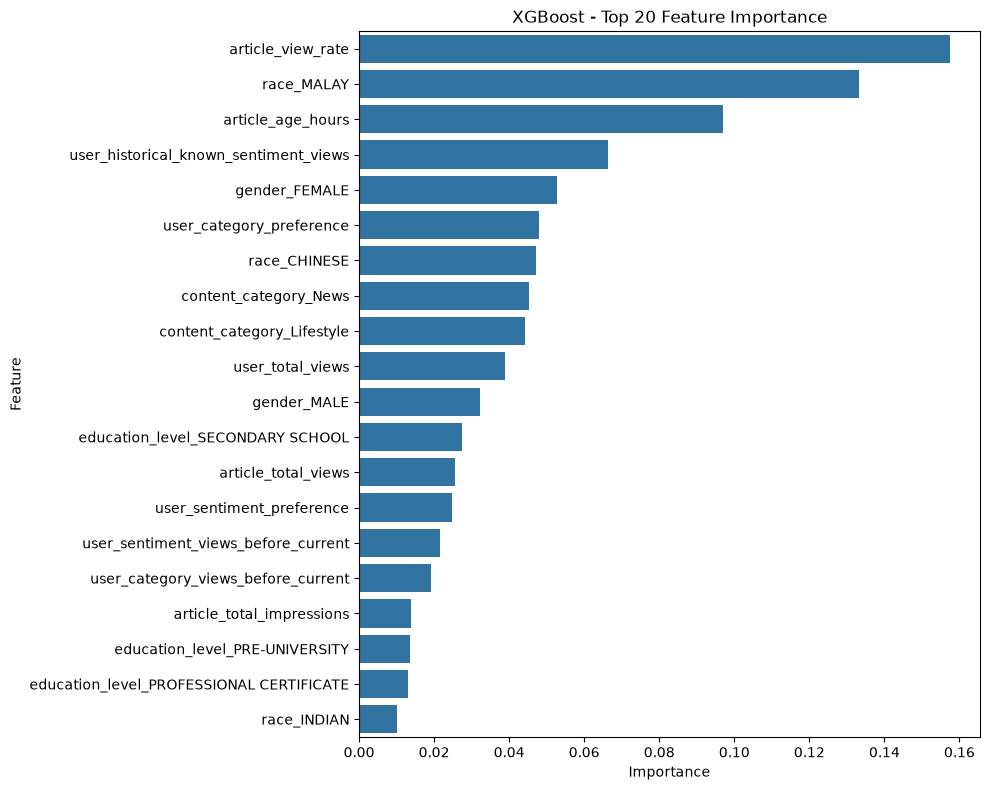

In [78]:
# feature importance
importance_df = pd.DataFrame()
importance_df["Feature"] = feature_names
importance_df["Importance"] = xgb_model.feature_importances_
importance_df = importance_df.sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(20), x="Importance", y="Feature")
plt.title("XGBoost - Top 20 Feature Importance")
plt.tight_layout()
plt.show()

PLAY AROUND WITH PREDICTION (XGBOOST)

In [79]:
# put xgboost probability into test set so can rank articles for each user.
df_test_result = df_test.copy()
df_test_result["view_probability"] = y_prob
df_test_result["predicted"] = y_pred

In [80]:
# list some users in test set that can try
print(df_test["cxuserid"].unique()[:10])

<ArrowStringArray>
['0017f8be-28cd-49f1-aa8f-f202d75222cb',
 '007ccc46-f247-4b3b-b50e-8557ad26ceb1',
 '01648aeb-e021-4c34-a1be-c52933e55814',
 '01b2ee61-291a-4fbb-9a9a-6c2dbfd632fc',
 '01c28e9a-e7eb-4036-bf99-81a74aa96200',
 '023e691e-e9af-4ef9-922f-03f8d9e09fea',
 '03321f18-5d79-447d-b08c-1182a013c408',
 '036df480-dc87-4866-9b94-b3b496ce5b16',
 '03c18872-a046-4509-a903-487200e1a867',
 '04728661-aa40-48e4-a05a-346866e33693']
Length: 10, dtype: str


Top articles for one user using XGBoost probability.

In [81]:
# change the cxuserid here to try other user
user_id = df_test["cxuserid"].iloc[0]

# take only this user rows
user_result = df_test_result[df_test_result["cxuserid"] == user_id]

# sort by probability, highest first
user_result = user_result.sort_values("view_probability", ascending=False)

# remove same article that appear many times
user_result = user_result.drop_duplicates(subset="content_id")

print("User:", user_id)
print("Predicted viewed")
display(user_result[["content_id", "content_title", "content_category", "view_probability", "predicted", "is_viewed"]].head())

User: 0017f8be-28cd-49f1-aa8f-f202d75222cb
Predicted viewed


,content_id,content_title,content_category,view_probability,predicted,is_viewed
11485,1937585.0,Ramanan calls for Anwar to serve second term a...,News,0.999990,1,1
10356,1931204.0,MRCB secures RM3.03bil Penang LRT rail systems...,Business,0.999989,1,1
10361,1931233.0,Australia politician admits texting 'my job is...,AseanPlus,0.999967,1,1
10688,1933987.0,Oil rises 3% as Iran tempers hopes of Hormuz r...,AseanPlus,0.999954,1,1


MODEL 3: HYRBID (XGBOOST + TFIDF SIMILARITY)

Baseline know what content same as user read, XGBoost know user and article behaviour. Hybrid put TF-IDF similarity as 1 more feature into XGBoost so it use both. Sort by user and time to build profile step by step.

In [82]:
# sort training and testing rows by user and datetime
df_train_hybrid = df_train.sort_values(["cxuserid", "record_datetime"]).copy().reset_index(drop=True)

df_test_hybrid = df_test.sort_values(["cxuserid", "record_datetime"]).copy().reset_index(drop=True)

# fit tf-idf using training articles only
df_train_content = (df_train_hybrid[["content_id", "content_text"]].drop_duplicates(subset="content_id").reset_index(drop=True)
)

Find tfidf similarity of the data to be fit into model

In [83]:
hybrid_tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

hybrid_tfidf.fit(df_train_content["content_text"])

print("Unique training contents:", df_train_content.shape)
print("Vocab size:", len(hybrid_tfidf.vocabulary_))

# convert article text into tf-idf vectors
train_vectors = hybrid_tfidf.transform(df_train_hybrid["content_text"])
test_vectors = hybrid_tfidf.transform(df_test_hybrid["content_text"])

# calculate training similarity using previous viewed articles only
# this prevents the current/future training interaction from entering the user profile
user_profile_sum = {}
user_profile_count = {}

train_similarity = []

for i, row in df_train_hybrid.iterrows():
    user_id = row["cxuserid"]

    if user_id in user_profile_sum:
        user_profile = user_profile_sum[user_id] / user_profile_count[user_id]
        score = cosine_similarity(
            train_vectors[i],
            user_profile.reshape(1, -1)
        )[0][0]
    else:
        score = 0

    train_similarity.append(score)

    # update user profile after scoring the current row
    if row["is_viewed"] == 1:
        article_vector = train_vectors[i].toarray().ravel()

        if user_id not in user_profile_sum:
            user_profile_sum[user_id] = article_vector.copy()
            user_profile_count[user_id] = 1
        else:
            user_profile_sum[user_id] += article_vector
            user_profile_count[user_id] += 1

# add similarity score into training data
df_train_hybrid["tfidf_similarity"] = train_similarity

# calculate test similarity using the user's training history
test_similarity = []

for i, row in df_test_hybrid.iterrows():
    user_id = row["cxuserid"]

    if user_id in user_profile_sum:
        user_profile = user_profile_sum[user_id] / user_profile_count[user_id]
        score = cosine_similarity(
            test_vectors[i],
            user_profile.reshape(1, -1)
        )[0][0]
    else:
        score = 0

    test_similarity.append(score)

# add similarity score into testing data
df_test_hybrid["tfidf_similarity"] = test_similarity

print("Training similarity:", df_train_hybrid["tfidf_similarity"].shape)
print("Testing similarity:", df_test_hybrid["tfidf_similarity"].shape)

Unique training contents: (6868, 2)
Vocab size: 5000
Training similarity: (10693,)
Testing similarity: (2765,)


Same features as XGBoost plus tfidf_similarity. So the only different is this add the similiarity

In [84]:
# use the same categorical and numerical features from the XGBoost model
hybrid_categorical = categorical.copy()
hybrid_numerical = numerical.copy()

# add TF-IDF cosine similarity as one more numerical feature
hybrid_numerical.append("tfidf_similarity")

# take only the features we need
# content_text is NOT included here
train_data = df_train_hybrid[hybrid_categorical + hybrid_numerical].copy()
test_data = df_test_hybrid[hybrid_categorical + hybrid_numerical].copy()

# one hot encode categorical columns
train_data = pd.get_dummies(train_data, columns=hybrid_categorical)
test_data = pd.get_dummies(test_data, columns=hybrid_categorical)

# test must have the same columns as train
test_data = test_data.reindex(columns=train_data.columns, fill_value=0)

X_train_hybrid = train_data.astype(float)
X_test_hybrid = test_data.astype(float)

y_train_hybrid = df_train_hybrid[target]
y_test_hybrid = df_test_hybrid[target]

# feature names after encode
hybrid_feature_names = list(X_train_hybrid.columns)

print("X_train_hybrid:", X_train_hybrid.shape)
print("X_test_hybrid:", X_test_hybrid.shape)
print(hybrid_feature_names)

X_train_hybrid: (10693, 41)
X_test_hybrid: (2765, 41)
['article_age_hours', 'user_total_views', 'user_category_views_before_current', 'user_category_preference', 'user_sentiment_views_before_current', 'user_historical_known_sentiment_views', 'user_sentiment_preference', 'article_total_views', 'article_total_impressions', 'article_view_rate', 'tfidf_similarity', 'gender_FEMALE', 'gender_MALE', 'race_CHINESE', 'race_INDIAN', 'race_MALAY', 'race_OTHERS', 'education_level_ADVANCE DIPLOMA', 'education_level_BACHELORS DEGREE', 'education_level_DIPLOMA', 'education_level_DISCLOSE', 'education_level_MASTER', 'education_level_PHD', 'education_level_PRE-UNIVERSITY', 'education_level_PROFESSIONAL CERTIFICATE', 'education_level_SECONDARY SCHOOL', 'content_category_AseanPlus', 'content_category_Business', 'content_category_ESG', 'content_category_Food', 'content_category_Lifestyle', 'content_category_Metro', 'content_category_News', 'content_category_Opinion', 'content_category_Sport', 'content_cat


Traing module use same settings as XGBoost before so the comparison is fair.

In [85]:
# train hybrid xgboost
hybrid_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="auc",
    n_jobs=-1
)

hybrid_model.fit(X_train_hybrid, y_train_hybrid)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Evaluate the model

In [86]:
# predict on test set
hybrid_y_pred = hybrid_model.predict(X_test_hybrid)
hybrid_y_prob = hybrid_model.predict_proba(X_test_hybrid)[:, 1]

# roc-auc need both 0 and 1 inside test
if y_test_hybrid.nunique() == 2:
    hybrid_roc_auc = roc_auc_score(y_test_hybrid, hybrid_y_prob)
else:
    hybrid_roc_auc = np.nan

evaluation = {}
evaluation["Accuracy"] = accuracy_score(y_test_hybrid, hybrid_y_pred)
evaluation["Precision"] = precision_score(y_test_hybrid, hybrid_y_pred, zero_division=0)
evaluation["Recall"] = recall_score(y_test_hybrid, hybrid_y_pred, zero_division=0)
evaluation["F1 Score"] = f1_score(y_test_hybrid, hybrid_y_pred, zero_division=0)
evaluation["ROC-AUC"] = hybrid_roc_auc

hybrid_evaluation_df = pd.DataFrame(evaluation.items(), columns=["Metric", "Score"])

display(hybrid_evaluation_df)
print(classification_report(y_test_hybrid, hybrid_y_pred, zero_division=0))

,Metric,Score
0,Accuracy,0.946835
1,Precision,0.960727
2,Recall,0.953461
3,F1 Score,0.957080
4,ROC-AUC,0.989108


              precision    recall  f1-score   support

           0       0.92      0.94      0.93      1046
           1       0.96      0.95      0.96      1719

    accuracy                           0.95      2765
   macro avg       0.94      0.94      0.94      2765
weighted avg       0.95      0.95      0.95      2765



Compare F1 and ROC-AUC:
1. Baseline F1 0.315 | ROC-AUC 0.817
2. XGBoost F1 0.949 | ROC-AUC 0.985
3. Hybrid F1 0.957 | ROC-AUC 0.989

Hybrid is the best. Only a bit better than XGBoost but better in all metrics, so TF-IDF score do help.

HYBRID XGBOOST FEATURE IMPORTANCE

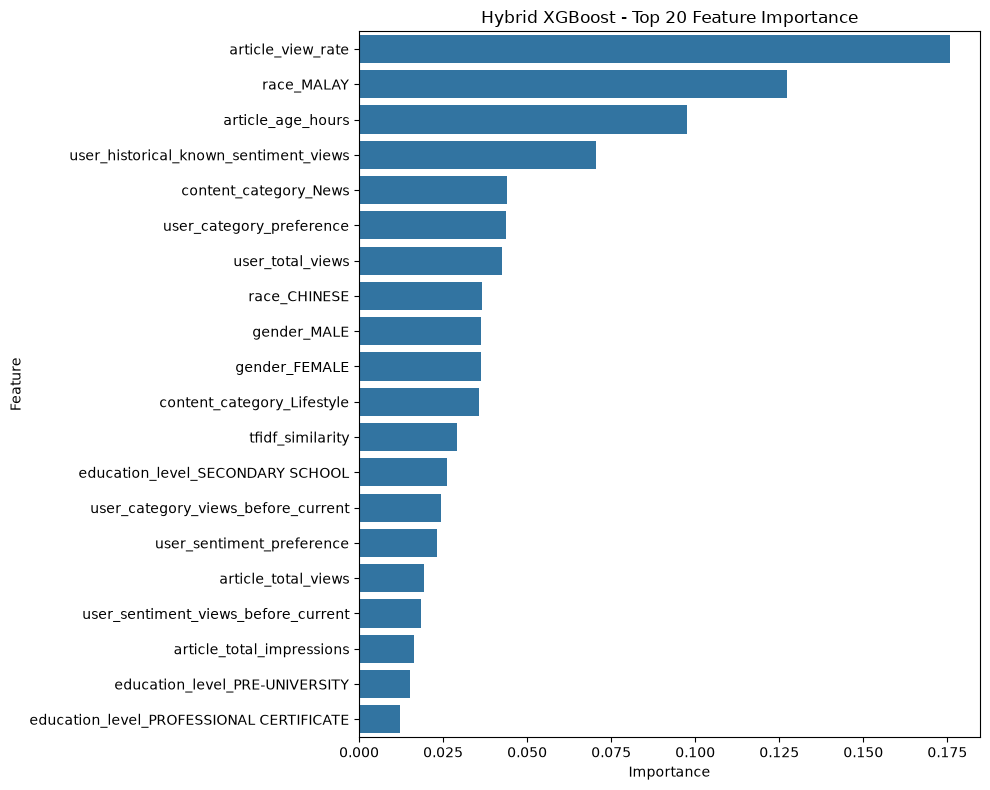

In [87]:
# feature importance
hybrid_importance_df = pd.DataFrame()
hybrid_importance_df["Feature"] = hybrid_feature_names
hybrid_importance_df["Importance"] = hybrid_model.feature_importances_
hybrid_importance_df = hybrid_importance_df.sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=hybrid_importance_df.head(20), x="Importance", y="Feature")
plt.title("Hybrid XGBoost - Top 20 Feature Importance")
plt.tight_layout()
plt.show()

PLAY AROUND WITH HYBRID PREDICTION

Put hybrid probability back into test rows.

In [88]:
# put hybrid xgboost probability into test set
df_test_hybrid_result = df_test_hybrid.copy()
df_test_hybrid_result["view_probability"] = hybrid_y_prob
df_test_hybrid_result["predicted"] = hybrid_y_pred

# list some users in test set that can try
print(df_test_hybrid["cxuserid"].unique()[:10])

<ArrowStringArray>
['0017f8be-28cd-49f1-aa8f-f202d75222cb',
 '007ccc46-f247-4b3b-b50e-8557ad26ceb1',
 '01648aeb-e021-4c34-a1be-c52933e55814',
 '01b2ee61-291a-4fbb-9a9a-6c2dbfd632fc',
 '01c28e9a-e7eb-4036-bf99-81a74aa96200',
 '023e691e-e9af-4ef9-922f-03f8d9e09fea',
 '03321f18-5d79-447d-b08c-1182a013c408',
 '036df480-dc87-4866-9b94-b3b496ce5b16',
 '03c18872-a046-4509-a903-487200e1a867',
 '04728661-aa40-48e4-a05a-346866e33693']
Length: 10, dtype: str


Top articles for one user using hybrid model, show similarity and probability

In [89]:
# change the cxuserid here to try other user
user_id = df_test_hybrid["cxuserid"].iloc[0]

# take only this user's rows
user_result = df_test_hybrid_result[
    df_test_hybrid_result["cxuserid"] == user_id
]

# sort by probability, highest first
user_result = user_result.sort_values("view_probability", ascending=False)

# remove same article that appear many times
user_result = user_result.drop_duplicates(subset="content_id")

print("User:", user_id)
print("Predicted viewed:")

display(
    user_result[
        [
            "content_id",
            "content_title",
            "content_category",
            "tfidf_similarity",
            "view_probability",
            "predicted",
            "is_viewed"
        ]
    ].head()
)

User: 0017f8be-28cd-49f1-aa8f-f202d75222cb
Predicted viewed:


,content_id,content_title,content_category,tfidf_similarity,view_probability,predicted,is_viewed
1,1931204.0,MRCB secures RM3.03bil Penang LRT rail systems...,Business,0.050001,0.999985,1,1
3,1937585.0,Ramanan calls for Anwar to serve second term a...,News,0.035389,0.999982,1,1
0,1931233.0,Australia politician admits texting 'my job is...,AseanPlus,0.261857,0.999978,1,1
2,1933987.0,Oil rises 3% as Iran tempers hopes of Hormuz r...,AseanPlus,0.051527,0.999959,1,1


Summary

1. Cleaned the data
2. Removed 918 duplicate
3. Binning the education
4. Kept missing sentiment as Unknown
5. All features only use data before current row
6. Split 80/20 by time for each user

TF-IDF only got ok ranking but miss most views. XGBoost much better. Hybrid is the best with F1 0.957 and ROC-AUC 0.989